In [7]:
#THis code is to check if the video is corrupted or not..
#If the video is corrupted delete the video.
import glob
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import face_recognition
#Check if the file is corrupted or not
def validate_video(vid_path,train_transforms):
      transform = train_transforms
      count = 20
      video_path = vid_path
      frames = []
      a = int(100/count)
      first_frame = np.random.randint(0,a)
      temp_video = video_path.split('/')[-1]
      for i,frame in enumerate(frame_extract(video_path)):
        frames.append(transform(frame))
        if(len(frames) == count):
          break
      frames = torch.stack(frames)
      frames = frames[:count]
      return frames
#extract a from from video
def frame_extract(path):
  vidObj = cv2.VideoCapture(path) 
  success = 1
  while success:
      success, image = vidObj.read()
      if success:
          yield image

im_size = 112
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
                                        transforms.ToPILImage(),
                                        transforms.Resize((im_size,im_size)),
                                        transforms.ToTensor(),
                                        transforms.Normalize(mean,std)])
video_fil_real =  glob.glob('./real_yt_face_videos/*.mp4')
video_fil_fake = glob.glob('./fake_yt_face_videos/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/DFDC_FAKE_Face_only_data/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/DFDC_REAL_Face_only_data/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/FF_Face_only_data/*.mp4')
print("Total no of real videos :" , len(video_fil_real))
print("Total no of fake videos :" , len(video_fil_fake))
print(video_fil_real)
count_real = 0
for i in video_fil_real:
  try:
    count_real+=1
    validate_video(i,train_transforms)
  except:
    print("Number of real video processed: " , count_real ," Remaining : " , (len(video_fil_real) - count_real))
    print("Corrupted real video is : " , i)
    continue
print((len(video_fil_real) - count_real))

count_fake = 0
for i in video_fil_fake:
  try:
    count_fake+=1
    validate_video(i,train_transforms)
  except:
    print("Number of fake video processed: " , count_fake ," Remaining : " , (len(video_fil_fake) - count_fake))
    print("Corrupted fake video is : " , i)
    continue
print((len(video_fil_fake) - count_fake))

Total no of real videos : 1000
Total no of fake videos : 1000
['./real_yt_face_videos/578.mp4', './real_yt_face_videos/544.mp4', './real_yt_face_videos/222.mp4', './real_yt_face_videos/236.mp4', './real_yt_face_videos/550.mp4', './real_yt_face_videos/587.mp4', './real_yt_face_videos/593.mp4', './real_yt_face_videos/008.mp4', './real_yt_face_videos/020.mp4', './real_yt_face_videos/746.mp4', './real_yt_face_videos/752.mp4', './real_yt_face_videos/034.mp4', './real_yt_face_videos/961.mp4', './real_yt_face_videos/975.mp4', './real_yt_face_videos/785.mp4', './real_yt_face_videos/791.mp4', './real_yt_face_videos/949.mp4', './real_yt_face_videos/168.mp4', './real_yt_face_videos/154.mp4', './real_yt_face_videos/632.mp4', './real_yt_face_videos/626.mp4', './real_yt_face_videos/140.mp4', './real_yt_face_videos/815.mp4', './real_yt_face_videos/801.mp4', './real_yt_face_videos/197.mp4', './real_yt_face_videos/829.mp4', './real_yt_face_videos/183.mp4', './real_yt_face_videos/418.mp4', './real_yt_fa

In [8]:
#to load preprocessod video to memory
import json
import glob
import numpy as np
import cv2
import copy
import random
video_files_real =  glob.glob('./real_yt_face_videos/*.mp4')

video_files_fake = glob.glob('./fake_yt_face_videos/*.mp4')

print(len(video_files_fake))
#random.shuffle(video_files)
frame_count = []
for video_file in video_files_real:
  cap = cv2.VideoCapture(video_file)
  if(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))<100):
    video_files_real.remove(video_file)
    continue
  frame_count.append(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

print("frames are " , frame_count)
print("Total no of video: " , len(frame_count))
print('Average frame per video:',np.mean(frame_count))

frame_count = []
for video_file in video_files_fake:
  cap = cv2.VideoCapture(video_file)
  if(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))<100):
    video_files_fake.remove(video_file)
    continue
  frame_count.append(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

print("frames are " , frame_count)
print("Total no of video: " , len(frame_count))
print('Average frame per video:',np.mean(frame_count))

1000
frames are  [148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 144, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 146, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 15

In [9]:
#to load preprocessod video to memory
import json
import glob
import numpy as np
import cv2
import copy
import random
video_files_real =  glob.glob('./real_yt_face_videos/*.mp4')

video_files_fake = glob.glob('./fake_yt_face_videos/*.mp4')

print(len(video_files_fake))
#random.shuffle(video_files)
frame_count = []
for video_file in video_files_real:
  cap = cv2.VideoCapture(video_file)
  if(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))<100):
    video_files_real.remove(video_file)
    continue
  frame_count.append(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

print("frames are " , frame_count)
print("Total no of video: " , len(frame_count))
print('Average frame per video:',np.mean(frame_count))

frame_count = []
for video_file in video_files_fake:
  cap = cv2.VideoCapture(video_file)
  if(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))<100):
    video_files_fake.remove(video_file)
    continue
  frame_count.append(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

print("frames are " , frame_count)
print("Total no of video: " , len(frame_count))
print('Average frame per video:',np.mean(frame_count))

1000
frames are  [148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 148, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 144, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 146, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 15

Train: 1600 videos (800 real, 800 fake)
Val: 400 videos (200 real, 200 fake)
Sample label: REAL


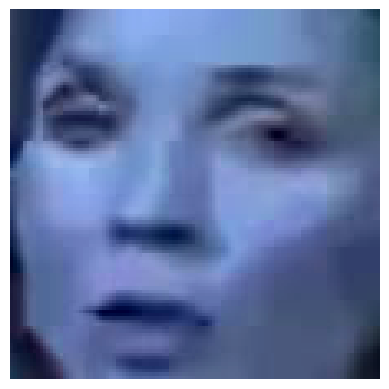

In [10]:
import os
import random
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Configuration
real_videos_folder = './real_yt_face_videos'
fake_videos_folder = './fake_yt_face_videos'
im_size = 112
sequence_length = 10
batch_size = 4

# 1. Load and label videos
def load_video_paths(real_dir, fake_dir):
    real_videos = [os.path.join(real_dir, f) for f in os.listdir(real_dir) 
                  if f.endswith(('.mp4', '.avi', '.mov'))]
    fake_videos = [os.path.join(fake_dir, f) for f in os.listdir(fake_dir)
                  if f.endswith(('.mp4', '.avi', '.mov'))]
    
    # Create labels (1=real, 0=fake)
    video_paths = real_videos + fake_videos
    labels = [1]*len(real_videos) + [0]*len(fake_videos)
    
    # Shuffle together
    combined = list(zip(video_paths, labels))
    random.shuffle(combined)
    video_paths, labels = zip(*combined)
    
    return video_paths, labels

# 2. Modified Dataset Class
class VideoDataset(Dataset):
    def __init__(self, video_paths, labels, sequence_length=60, transform=None):
        self.video_paths = video_paths
        self.labels = labels
        self.transform = transform
        self.seq_length = sequence_length
        
    def __len__(self):
        return len(self.video_paths)
    
    def __getitem__(self, idx):
        video_path = self.video_paths[idx]
        label = self.labels[idx]
        
        frames = []
        for i, frame in enumerate(self.frame_extract(video_path)):
            if self.transform:
                frame = self.transform(frame)
            frames.append(frame)
            if len(frames) == self.seq_length:
                break
                
        # Pad if video is shorter than sequence length
        while len(frames) < self.seq_length:
            frames.append(frames[-1])
            
        return torch.stack(frames), torch.tensor(label, dtype=torch.long)
    
    def frame_extract(self, path):
        cap = cv2.VideoCapture(path)
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            yield frame
        cap.release()

# 3. Data Preparation Pipeline
# Load and split data
video_paths, labels = load_video_paths(real_videos_folder, fake_videos_folder)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    video_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

# Print dataset stats
print(f"Train: {len(train_paths)} videos ({sum(train_labels)} real, {len(train_labels)-sum(train_labels)} fake)")
print(f"Val: {len(val_paths)} videos ({sum(val_labels)} real, {len(val_labels)-sum(val_labels)} fake)")

# Transforms
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Create datasets and dataloaders
train_dataset = VideoDataset(train_paths, train_labels, sequence_length, train_transforms)
val_dataset = VideoDataset(val_paths, val_labels, sequence_length, val_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, 
                         shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size,
                       shuffle=False, num_workers=0, pin_memory=True)

# Visualization function
def im_plot(tensor):
    image = tensor.cpu().numpy().transpose(1, 2, 0)
    image = image * std + mean  # Unnormalize
    image = np.clip(image, 0, 1)
    plt.imshow(image)
    plt.axis('off')
    plt.show()

# Test visualization
sample_frames, sample_label = train_dataset[4]
print(f"Sample label: {'REAL' if sample_label == 1 else 'FAKE'}")
im_plot(sample_frames[0])  # Show first frame

MODEL

In [11]:
#Model with feature visualization
from torch import nn
from torchvision import models
class Model(nn.Module):
    def __init__(self, num_classes,latent_dim= 2048, lstm_layers=1 , hidden_dim = 2048, bidirectional = False):
        super(Model, self).__init__()
        model = models.resnext50_32x4d(pretrained = True) #Residual Network CNN
        self.model = nn.Sequential(*list(model.children())[:-2])
        self.lstm = nn.LSTM(latent_dim,hidden_dim, lstm_layers,  bidirectional)
        self.relu = nn.LeakyReLU()
        self.dp = nn.Dropout(0.4)
        self.linear1 = nn.Linear(2048,num_classes)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
    def forward(self, x):
        batch_size,seq_length, c, h, w = x.shape
        x = x.view(batch_size * seq_length, c, h, w)
        fmap = self.model(x)
        x = self.avgpool(fmap)
        x = x.view(batch_size,seq_length,2048)
        x_lstm,_ = self.lstm(x,None)
        return fmap,self.dp(self.linear1(torch.mean(x_lstm,dim = 1)))

In [35]:
from torch import nn
from torchvision import models
import torch
from torch.nn import functional as F

class EnhancedVideoModel(nn.Module):
    def __init__(self, num_classes, latent_dim=2048, lstm_layers=2, hidden_dim=2048):
        super(EnhancedVideoModel, self).__init__()
        
        # Enhanced CNN Backbone with attention
        self.cnn = models.efficientnet_b3(pretrained=True)
        self.cnn_backbone = nn.Sequential(
            *list(self.cnn.children())[:-3],  # Deeper feature extraction
            ChannelAttention(1536)  # For EfficientNet-B3 features
        )
        
        # Temporal Modeling with LayerNorm and dropout
        self.lstm = nn.LSTM(
            input_size=1536,  # Matching EfficientNet-B3 features
            hidden_size=hidden_dim,
            num_layers=lstm_layers,
            dropout=0.3 if lstm_layers > 1 else 0,
            batch_first=True
        )
        self.lstm_norm = nn.LayerNorm(hidden_dim)
        
        # Classification Head with dense blocks
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.BatchNorm1d(hidden_dim//2),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.5),
            nn.Linear(hidden_dim//2, num_classes)
        )
        
        # Spatial pooling
        self.adaptive_pool = nn.AdaptiveAvgPool2d(1)
        
        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(module.weight)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.LSTM):
                for name, param in module.named_parameters():
                    if 'weight_ih' in name:
                        nn.init.orthogonal_(param.data)
                    elif 'weight_hh' in name:
                        nn.init.orthogonal_(param.data)
                    elif 'bias' in name:
                        nn.init.constant_(param.data, 0)

    def forward(self, x):
        # Input shape: (batch, seq_len, C, H, W)
        batch_size, seq_len = x.size(0), x.size(1)
        
        # CNN Feature Extraction
        x = x.view(batch_size * seq_len, *x.shape[2:])
        feature_maps = self.cnn_backbone(x)
        
        # Temporal Pooling
        x = self.adaptive_pool(feature_maps)
        x = x.view(batch_size, seq_len, -1)
        
        # LSTM with LayerNorm
        x_lstm, _ = self.lstm(x)
        x_lstm = self.lstm_norm(x_lstm)
        
        # Temporal Attention
        x = torch.mean(x_lstm, dim=1)  # Simple temporal aggregation
        
        # Classification
        return feature_maps, self.classifier(x)

class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction, in_channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

NO CHANGE

In [ ]:
import torch
import numpy as np

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = EnhancedVideoModel(2).to(device)

input_tensor = torch.from_numpy(np.empty((1, 20, 3, 112, 112))).float().to(device)

a, b = model(input_tensor)


In [34]:
# First define the EnhancedVideoModel class from previous answer here
# Then modify your test code like this:

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Instantiate with correct class name and proper parameters
model = EnhancedVideoModel(num_classes=2).to(device)  # Note the class name change

# Create test input with proper normalization (critical for EfficientNet)
input_tensor = torch.randn(1, 20, 3, 112, 112).float().to(device)  # Using random data

# Forward pass
with torch.no_grad():
    feature_maps, predictions = model(input_tensor)

/Users/satispanda/Desktop/DLCV PROJECT/venv/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B3_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /Users/satispanda/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth
100%|██████████| 47.2M/47.2M [00:01<00:00, 32.9MB/s]


RuntimeError: linear(): input and weight.T shapes cannot be multiplied (20x3 and 1536x96)

In [29]:
import torch
from torch.autograd import Variable
import time
import os
import sys

# Set device
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

def train_epoch(epoch, num_epochs, data_loader, model, criterion, optimizer):
    model.train()
    losses = AverageMeter()
    accuracies = AverageMeter()
    for i, (inputs, targets) in enumerate(data_loader):
        inputs = inputs.to(device)
        targets = targets.to(device).long()

        _, outputs = model(inputs)
        loss = criterion(outputs, targets)
        acc = calculate_accuracy(outputs, targets)

        losses.update(loss.item(), inputs.size(0))
        accuracies.update(acc, inputs.size(0))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        sys.stdout.write(
            "\r[Epoch %d/%d] [Batch %d / %d] [Loss: %f, Acc: %.2f%%]"
            % (
                epoch,
                num_epochs,
                i,
                len(data_loader),
                losses.avg,
                accuracies.avg
            )
        )
    torch.save(model.state_dict(), './trial2.pt')
    return losses.avg, accuracies.avg

def test(epoch, model, data_loader, criterion):
    print('Testing')
    model.eval()
    losses = AverageMeter()
    accuracies = AverageMeter()
    pred = []
    true = []

    with torch.no_grad():
        for i, (inputs, targets) in enumerate(data_loader):
            inputs = inputs.to(device)
            targets = targets.to(device).long()

            _, outputs = model(inputs)
            loss = criterion(outputs, targets)
            acc = calculate_accuracy(outputs, targets)

            _, p = torch.max(outputs, 1)

            true += targets.cpu().numpy().reshape(len(targets)).tolist()
            pred += p.cpu().numpy().reshape(len(p)).tolist()

            losses.update(loss.item(), inputs.size(0))
            accuracies.update(acc, inputs.size(0))

            sys.stdout.write(
                "\r[Batch %d / %d]  [Loss: %f, Acc: %.2f%%]"
                % (
                    i,
                    len(data_loader),
                    losses.avg,
                    accuracies.avg
                )
            )
        print('\nAccuracy {}'.format(accuracies.avg))
    return true, pred, losses.avg, accuracies.avg

class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

def calculate_accuracy(outputs, targets):
    batch_size = targets.size(0)
    _, pred = outputs.topk(1, 1, True)
    pred = pred.t()
    correct = pred.eq(targets.view(1, -1))
    n_correct_elems = correct.float().sum().item()
    return 100 * n_correct_elems / batch_size


In [30]:
import seaborn as sn
from sklearn.metrics import confusion_matrix
import pandas as pd
#Output confusion matrix
def print_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    print('True positive = ', cm[0][0])
    print('False positive = ', cm[0][1])
    print('False negative = ', cm[1][0])
    print('True negative = ', cm[1][1])
    print('\n')
    df_cm = pd.DataFrame(cm, range(2), range(2))
    sn.set(font_scale=1.4) # for label size
    sn.heatmap(df_cm, annot=True, annot_kws={"size": 16}) # font size
    plt.ylabel('Actual label', size = 20)
    plt.xlabel('Predicted label', size = 20)
    plt.xticks(np.arange(2), ['Fake', 'Real'], size = 16)
    plt.yticks(np.arange(2), ['Fake', 'Real'], size = 16)
    plt.ylim([2, 0])
    plt.show()
    calculated_acc = (cm[0][0]+cm[1][1])/(cm[0][0]+cm[0][1]+cm[1][0]+ cm[1][1])
    print("Calculated Accuracy",calculated_acc*100)

In [31]:
def plot_loss(train_loss_avg,test_loss_avg,num_epochs):
  loss_train = train_loss_avg
  loss_val = test_loss_avg
  print(num_epochs)
  epochs = range(1,num_epochs+1)
  plt.plot(epochs, loss_train, 'g', label='Training loss')
  plt.plot(epochs, loss_val, 'b', label='validation loss')
  plt.title('Training and Validation loss')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()
  plt.show()
def plot_accuracy(train_accuracy,test_accuracy,num_epochs):
  loss_train = train_accuracy
  loss_val = test_accuracy
  epochs = range(1,num_epochs+1)
  plt.plot(epochs, loss_train, 'g', label='Training accuracy')
  plt.plot(epochs, loss_val, 'b', label='validation accuracy')
  plt.title('Training and Validation accuracy')
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.legend()
  plt.show()

In [32]:
#learning rate
lr = 1e-5#0.001
#number of epochs 
num_epochs = 20

optimizer = torch.optim.Adam(model.parameters(), lr= lr,weight_decay = 1e-5)

#class_weights = torch.from_numpy(np.asarray([1,15])).type(torch.FloatTensor).cuda()
#criterion = nn.CrossEntropyLoss(weight = class_weights).cuda()
criterion = nn.CrossEntropyLoss().cuda()
train_loss_avg =[]
train_accuracy = []
test_loss_avg = []
test_accuracy = []
for epoch in range(1,num_epochs+1):
    l, acc = train_epoch(epoch,num_epochs,train_loader,model,criterion,optimizer)
    train_loss_avg.append(l)
    train_accuracy.append(acc)
    true,pred,tl,t_acc = test(epoch,model,val_loader,criterion)
    test_loss_avg.append(tl)
    test_accuracy.append(t_acc)
plot_loss(train_loss_avg,test_loss_avg,len(train_loss_avg))
plot_accuracy(train_accuracy,test_accuracy,len(train_accuracy))
print(confusion_matrix(true,pred))
print_confusion_matrix(true,pred)

[Epoch 1/20] [Batch 399 / 400] [Loss: 0.681230, Acc: 59.31%]Testing
[Batch 99 / 100]  [Loss: 0.623680, Acc: 65.25%]
Accuracy 65.25
[Epoch 2/20] [Batch 399 / 400] [Loss: 0.593205, Acc: 67.81%]Testing
[Batch 99 / 100]  [Loss: 0.592885, Acc: 68.25%]
Accuracy 68.25
[Epoch 3/20] [Batch 399 / 400] [Loss: 0.547920, Acc: 71.25%]Testing
[Batch 99 / 100]  [Loss: 0.596291, Acc: 67.25%]
Accuracy 67.25
[Epoch 4/20] [Batch 399 / 400] [Loss: 0.497350, Acc: 75.69%]Testing
[Batch 99 / 100]  [Loss: 0.663493, Acc: 66.00%]
Accuracy 66.0
[Epoch 5/20] [Batch 277 / 400] [Loss: 0.472827, Acc: 77.16%]

KeyboardInterrupt: 

In [ ]:
import torch
import numpy as np

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = Model(2).to(device)
print(f"Using device: {device}")

path_to_model = './trial2.pt'
model.load_state_dict(torch.load(path_to_model))


/Users/satispanda/Desktop/DLCV PROJECT/venv/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/satispanda/Desktop/DLCV PROJECT/venv/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt50_32X4D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt50_32X4D_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Using device: mps


<All keys matched successfully>

In [ ]:
plot_loss(train_loss_avg,test_loss_avg,len(train_loss_avg))
plot_accuracy(train_accuracy,test_accuracy,len(train_accuracy))
print(confusion_matrix(true,pred))
print_confusion_matrix(true,pred)

NameError: name 'train_loss_avg' is not defined